# 文の長さや文字数の基本統計をとる

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/06_corpus_statistics/corpus_stats.ipynb)

NLP クックブック 06-01 ／ コーパスの統計と可視化

コーパスの規模感（文数、平均文長、長さの分布）をまず把握したい。

In [1]:
!pip install -q fugashi unidic-lite

In [2]:
import io, re, urllib.request, zipfile
import pandas as pd
from fugashi import Tagger

def aozora(url):
    with urllib.request.urlopen(url) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
    text = z.read(z.namelist()[0]).decode("cp932")
    text = re.split(r"-{50,}", text)[2].split("底本：")[0]
    return re.sub(r"《.+?》|［＃.+?］|｜", "", text).replace("\r\n", "\n").strip()

tagger = Tagger()
text = aozora("https://www.aozora.gr.jp/cards/000148/files/752_ruby_2438.zip")
sents = [s.strip() for s in re.split(r"(?<=[。？！])|\n", text) if s and s.strip()]
df = pd.DataFrame({"sentence": sents})
df["chars"] = df["sentence"].str.len()
df["words"] = df["sentence"].map(lambda s: len(tagger(s)))
df[["chars", "words"]].describe(percentiles=[0.5, 0.9, 0.99]).round(1)

,chars,words
count,2732.0,2732.0
mean,32.3,21.1
std,21.6,14.2
min,1.0,1.0
50%,27.0,18.0
90%,61.0,40.0
99%,106.7,69.0
max,163.0,111.0


最長の文: 先生はご鄭寧に、自席から、座敷の端の末座まで行って、慇懃に一同に挨拶をした上、今般は一身上の都合で九州へ参る事になりましたについて、諸先生方が小生のためにこの盛 ...
最短の文: ['一', '二', '三', '四', '五']


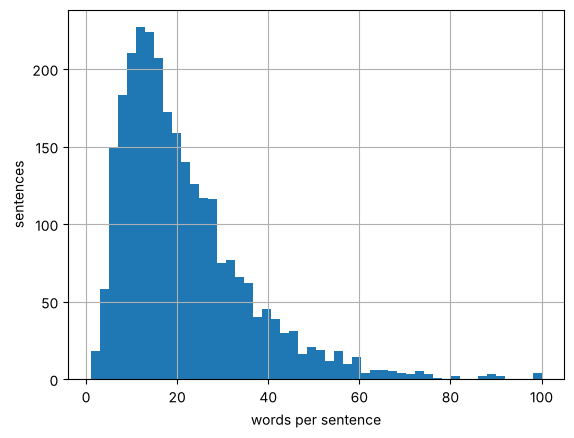

In [3]:
ax = df["words"].clip(upper=100).hist(bins=50)
ax.set_xlabel("words per sentence"); ax.set_ylabel("sentences")

print("最長の文:", df.loc[df["words"].idxmax(), "sentence"][:80], "...")
print("最短の文:", df.nsmallest(5, "chars")["sentence"].tolist())

- 極端に長い文・短い文は、文分割の失敗やノイズであることが多い。最大・最小の実例は必ず目で見る。